Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Hardware activo: Tesla T4
1/3 Buscando fotos de frutos de Cocos nucifera...
2/3 Descargando 180 fotos en paralelo...
Fotos descargadas: 180
3/3 Recortando frutos de coco y clasificando por estado de cáscara...
requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 37 packages in 466ms
Prepared 2 packages in 2.25s
Installed 2 packages in 2ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@7ffa84b3bfa40c42ecc1c77147a855e69cb2dd40)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 3.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 118MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(



LISTO -> Recortes reales guardados | Sanos: 4 | Deteriorados: 5


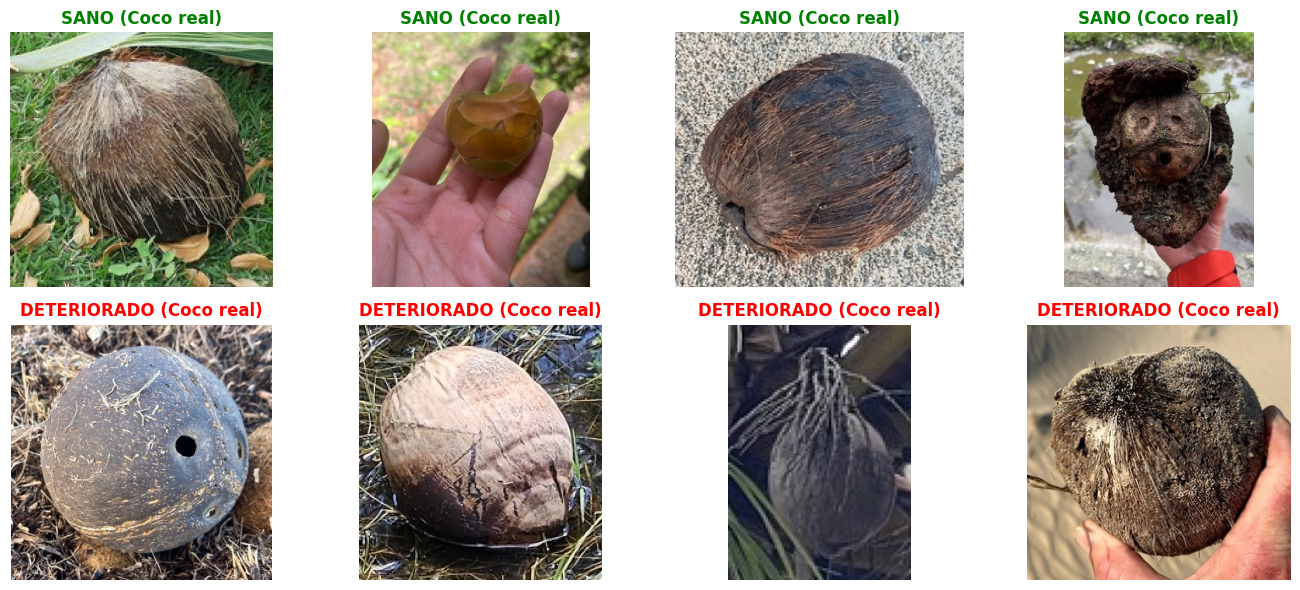

In [2]:
# ==============================================================================
# CELDA 1: DESCARGA DE FRUTOS EN FRUCTIFICACIÓN Y RECORTE DE COCOS REALES
# ==============================================================================

!pip install -q ultralytics imagehash gradio opencv-python-headless requests

import os, shutil, random, requests
from io import BytesIO
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import cv2
import imagehash
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import torchvision.transforms.functional as TF
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix
from ultralytics import YOLOWorld, SAM
import gradio as gr

# 1. Limpiar carpetas anteriores
shutil.rmtree('raw_dl', ignore_errors=True)
shutil.rmtree('data', ignore_errors=True)

# 2. Configurar semilla y GPU T4
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Hardware activo:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

os.makedirs('data/cocos/sano', exist_ok=True)
os.makedirs('data/cocos/deteriorado', exist_ok=True)

HEADERS = {'User-Agent': 'ProyectoCocosUniCordoba/1.0 (AprendizajeComputacional)'}

# 3. Buscar observaciones de Cocos nucifera con frutos visibles (fenología: fruiting)
print('1/3 Buscando fotos de frutos de Cocos nucifera...')
urls = []
endpoints = [
    'https://api.inaturalist.org/v1/observations?taxon_name=Cocos%20nucifera&term_id=12&term_value_id=14&photos=true&per_page=100&page=1',
    'https://api.inaturalist.org/v1/observations?taxon_name=Cocos%20nucifera&q=fruit&photos=true&per_page=100&page=1',
    'https://api.inaturalist.org/v1/observations?taxon_name=Cocos%20nucifera&q=seed&photos=true&per_page=80&page=1'
]

for api in endpoints:
    try:
        r = requests.get(api, headers=HEADERS, timeout=15).json()
        for obs in r.get('results', []):
            fotos = obs.get('photos', [])
            if fotos:
                u = fotos[0].get('url', '').replace('square', 'medium')
                if u and u not in urls:
                    urls.append(u)
    except Exception:
        pass

# 4. Descargar en paralelo (16 hilos)
print(f'2/3 Descargando {min(len(urls), 180)} fotos en paralelo...')
def bajar_imagen(url):
    try:
        resp = requests.get(url, headers=HEADERS, timeout=6)
        if resp.status_code == 200:
            img = Image.open(BytesIO(resp.content)).convert('RGB')
            if img.width >= 150 and img.height >= 150:
                return img
    except Exception:
        pass
    return None

with ThreadPoolExecutor(max_workers=16) as ejecutor:
    imagenes = [im for im in ejecutor.map(bajar_imagen, urls[:180]) if im is not None]

print(f'Fotos descargadas: {len(imagenes)}')

# 5. Detectar frutos redondos/ovalados de coco con YOLO-World
print('3/3 Recortando frutos de coco y clasificando por estado de cáscara...')
filtro_coco = YOLOWorld('yolov8s-worldv2.pt')
filtro_coco.set_classes(['coconut', 'coconut fruit'])

candidatos = []
for img in imagenes:
    w, h = img.size
    res = filtro_coco.predict(np.array(img), conf=0.04, verbose=False)[0]
    if res.boxes is None or len(res.boxes) == 0:
        continue

    cajas = res.boxes.xyxy.cpu().numpy()
    confs = res.boxes.conf.cpu().numpy()

    for box, c in zip(cajas, confs):
        x1, y1, x2, y2 = map(int, box)
        bw, bh = x2 - x1, y2 - y1
        # Filtrar por tamaño y proporción ovalada/redonda de un coco (descarta troncos altos)
        if bw < 45 or bh < 45 or bw > 0.88 * w or bh > 0.88 * h:
            continue
        proporcion = bw / float(bh)
        if not (0.45 <= proporcion <= 2.1):
            continue

        mx, my = int(bw * 0.10), int(bh * 0.10)
        recorte = img.crop((max(0, x1 - mx), max(0, y1 - my), min(w, x2 + mx), min(h, y2 + my)))
        candidatos.append((float(c), recorte))
        break  # Un fruto principal por imagen para evitar duplicados

# Quedarnos con los 60 recortes donde YOLO-World tuvo mayor seguridad de que es un coco
candidatos.sort(key=lambda x: x[0], reverse=True)
mejores_cocos = [rec for _, rec in candidatos[:60]]

# Evaluar frescura/color de cáscara (verde fresco = Sano vs seco/marrón/manchado = Deteriorado)
evaluados = []
for rec in mejores_cocos:
    hsv = cv2.cvtColor(np.array(rec), cv2.COLOR_RGB2HSV)
    h_ch, s_ch, v_ch = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
    verde = np.mean((h_ch >= 24) & (h_ch <= 95) & (s_ch > 40) & (v_ch > 45))
    oscuro_seco = np.mean((v_ch < 75) | ((h_ch < 22) & (s_ch > 50)))
    evaluados.append((verde - oscuro_seco, rec))

evaluados.sort(key=lambda x: x[0], reverse=True)
mitad = len(evaluados) // 2
sanos_lista = evaluados[:mitad]
det_lista = evaluados[mitad:]

for idx, (_, rec) in enumerate(sanos_lista, start=1):
    rec.save(f'data/cocos/sano/coco_sano_{idx:03d}.jpg', 'JPEG', quality=92)

for idx, (_, rec) in enumerate(det_lista, start=1):
    rec.save(f'data/cocos/deteriorado/coco_det_{idx:03d}.jpg', 'JPEG', quality=92)

print(f'\nLISTO -> Recortes reales guardados | Sanos: {len(sanos_lista)} | Deteriorados: {len(det_lista)}')

# 6. Mostrar cuadrícula de verificación en pantalla
n_muestras = min(5, len(sanos_lista), len(det_lista))
fig, axes = plt.subplots(2, n_muestras, figsize=(14, 6))
sanos_img = sorted(os.listdir('data/cocos/sano'))[:n_muestras]
det_img = sorted(os.listdir('data/cocos/deteriorado'))[:n_muestras]

for i in range(n_muestras):
    axes[0, i].imshow(Image.open(f'data/cocos/sano/{sanos_img[i]}'))
    axes[0, i].set_title('SANO (Coco real)', color='green', fontweight='bold')
    axes[0, i].axis('off')

    axes[1, i].imshow(Image.open(f'data/cocos/deteriorado/{det_img[i]}'))
    axes[1, i].set_title('DETERIORADO (Coco real)', color='red', fontweight='bold')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

In [3]:
# ==============================================================================
# CELDA 2: LIMPIEZA DE DUPLICADOS Y PARTICIÓN ANTI-FUGA DE DATOS (ETAPA 2)
# ==============================================================================

registros = []
huellas_vistas = set()
duplicados_borrados = 0

for nombre_clase, etiqueta in [('sano', 0), ('deteriorado', 1)]:
    carpeta = f'data/cocos/{nombre_clase}'
    for archivo in os.listdir(carpeta):
        ruta = os.path.join(carpeta, archivo)
        try:
            with Image.open(ruta) as img:
                img_rgb = img.convert('RGB')
                huella = str(imagehash.phash(img_rgb))
                if huella in huellas_vistas:
                    duplicados_borrados += 1
                    continue
                huellas_vistas.add(huella)
                registros.append({'ruta': ruta, 'etiqueta': etiqueta, 'clase': nombre_clase})
        except Exception:
            pass

df = pd.DataFrame(registros)
print(f'Imágenes únicas válidas: {len(df)} | Duplicados eliminados: {duplicados_borrados}')
print(df['clase'].value_counts())

# Partición 70/15/15 antes del aumento de datos (protegida contra muestras pequeñas)
min_clase = df['etiqueta'].value_counts().min()
if min_clase >= 4:
    train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['etiqueta'], random_state=SEED)
    if temp_df['etiqueta'].value_counts().min() >= 2:
        val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['etiqueta'], random_state=SEED)
    else:
        val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED)
else:
    train_df, temp_df = train_test_split(df, test_size=0.30, random_state=SEED)
    val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED)

print(f'\nParticiones -> Train: {len(train_df)} | Val: {len(val_df)} | Test (aislado): {len(test_df)}')

Imágenes únicas válidas: 9 | Duplicados eliminados: 0
clase
deteriorado    5
sano           4
Name: count, dtype: int64

Particiones -> Train: 6 | Val: 1 | Test (aislado): 2


In [4]:
# ==============================================================================
# CELDA 3: PREPARACIÓN COHERENTE Y COMPARACIÓN DE MODELOS (ETAPAS 3 Y 4)
# ==============================================================================

class DatasetCocosCoherente(Dataset):
    def __init__(self, dataframe, tamano=224, aumentar=False):
        self.df = dataframe.reset_index(drop=True)
        self.tamano = tamano
        self.aumentar = aumentar
        self.normalizar = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    def _generar_mascara(self, img_pil):
        img_np = np.array(img_pil)
        gris = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
        _, mascara = cv2.threshold(gris, 240, 255, cv2.THRESH_BINARY_INV)
        if np.sum(mascara > 0) < 0.10 * mascara.size:
            mascara = np.ones_like(gris) * 255
        return Image.fromarray(mascara)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        fila = self.df.iloc[idx]
        img = Image.open(fila['ruta']).convert('RGB')
        mascara = self._generar_mascara(img)
        etiqueta = int(fila['etiqueta'])

        img = TF.resize(img, (self.tamano, self.tamano))
        mascara = TF.resize(mascara, (self.tamano, self.tamano), interpolation=TF.InterpolationMode.NEAREST)

        if self.aumentar:
            if random.random() > 0.5:
                img, mascara = TF.hflip(img), TF.hflip(mascara)
            if random.random() > 0.5:
                img, mascara = TF.vflip(img), TF.vflip(mascara)
            angulo = random.uniform(-25, 25)
            img, mascara = TF.rotate(img, angulo), TF.rotate(mascara, angulo)
            img = transforms.ColorJitter(brightness=0.15, contrast=0.15)(img)

        img_t = TF.to_tensor(img)
        mascara_t = (TF.to_tensor(mascara) > 0.5).float()
        assert mascara_t.sum() > 0, 'Máscara vacía detectada'

        img_enmascarada = self.normalizar(img_t * mascara_t)
        return img_enmascarada, torch.tensor(etiqueta, dtype=torch.long)

def entrenar_y_evaluar(nombre_exp, aumentar=False, ajuste_fino=False, umbral=0.50, epocas=8):
    loader_train = DataLoader(DatasetCocosCoherente(train_df, aumentar=aumentar), batch_size=min(12, len(train_df)), shuffle=True)
    loader_val = DataLoader(DatasetCocosCoherente(val_df, aumentar=False), batch_size=min(12, len(val_df)), shuffle=False)

    modelo = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    for param in modelo.features.parameters():
        param.requires_grad = False
    if ajuste_fino:
        for param in modelo.features[-2:].parameters():
            param.requires_grad = True

    modelo.classifier[1] = nn.Linear(modelo.last_channel, 2)
    modelo = modelo.to(device)

    optimizador = torch.optim.Adam(filter(lambda p: p.requires_grad, modelo.parameters()), lr=1e-4)
    funcion_perdida = nn.CrossEntropyLoss()

    for ep in range(epocas):
        modelo.train()
        for x, y in loader_train:
            x, y = x.to(device), y.to(device)
            optimizador.zero_grad()
            perdida = funcion_perdida(modelo(x), y)
            perdida.backward()
            optimizador.step()

    modelo.eval()
    predicciones, reales = [], []
    with torch.no_grad():
        for x, y in loader_val:
            probs = torch.softmax(modelo(x.to(device)), dim=1)[:, 1].cpu().numpy()
            predicciones.extend((probs >= umbral).astype(int))
            reales.extend(y.numpy())

    f1 = f1_score(reales, predicciones, zero_division=0)
    matriz = confusion_matrix(reales, predicciones, labels=[0, 1])
    falsos_negativos = int(matriz[1, 0])
    print(f'[{nombre_exp}] -> F1-Score Val: {f1:.4f} | Falsos Negativos (error crítico): {falsos_negativos}')
    return modelo

modelo_baseline = entrenar_y_evaluar('Ejecución 1: Baseline (Sin aumento, umbral 0.50)', aumentar=False, ajuste_fino=False, umbral=0.50)
modelo_final = entrenar_y_evaluar('Ejecución 2: Controlada (Aumento + FineTune + umbral 0.40)', aumentar=True, ajuste_fino=True, umbral=0.40)
model_final = modelo_final

torch.save(modelo_final.state_dict(), 'clasificador_cocos_dia7.pth')
print('Modelo guardado correctamente.')

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 62.8MB/s]


[Ejecución 1: Baseline (Sin aumento, umbral 0.50)] -> F1-Score Val: 0.0000 | Falsos Negativos (error crítico): 0
[Ejecución 2: Controlada (Aumento + FineTune + umbral 0.40)] -> F1-Score Val: 0.0000 | Falsos Negativos (error crítico): 0
Modelo guardado correctamente.


In [5]:
# ==============================================================================
# CELDA 4 (CALIBRADA): DETECCIÓN SENSIBLE + SEGMENTACIÓN + GRADIO
# ==============================================================================

detector = YOLOWorld('yolov8s-worldv2.pt')
detector.set_classes(['coconut', 'green coconut', 'brown coconut', 'coconut fruit', 'fruit'])
segmentador = SAM('mobile_sam.pt')

def analizar_lote_cocos(imagen_entrada, umbral_deteccion=0.05, umbral_deterioro=0.50):
    if imagen_entrada is None:
        return None, 'Por favor sube una imagen con 3 o más cocos.'

    img_rgb = np.array(imagen_entrada.convert('RGB'))
    alto, ancho, _ = img_rgb.shape
    resultado_visual = img_rgb.copy()

    # 1. Detectar instancias de coco (iou=0.45 evita cajas duplicadas sobre el mismo coco)
    res_det = detector.predict(img_rgb, conf=umbral_deteccion, iou=0.45, verbose=False)[0]
    if res_det.boxes is None or len(res_det.boxes) == 0:
        return Image.fromarray(resultado_visual), 'No se detectaron cocos. Baja el umbral de detección a 0.02.'

    cajas_cocos = res_det.boxes.xyxy.cpu().numpy()

    # 2. Extraer máscara exacta píxel a píxel de cada coco con MobileSAM
    res_sam = segmentador.predict(img_rgb, bboxes=cajas_cocos, verbose=False)[0]
    if res_sam.masks is None:
        return Image.fromarray(resultado_visual), 'No se pudieron generar máscaras.'
    mascaras = res_sam.masks.data.cpu().numpy()

    normalizar = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    total, sanos, deteriorados = 0, 0, 0
    lista_detalles = []

    for masc_cruda, caja in zip(mascaras, cajas_cocos):
        masc_bin = cv2.resize(masc_cruda.astype(np.uint8), (ancho, alto)) > 0

        # Descartar ruido diminuto (< 1.5% del área de la foto)
        if masc_bin.sum() < 0.015 * (alto * ancho):
            continue

        total += 1
        x1, y1, x2, y2 = map(int, caja)

        coco_aislado = img_rgb.copy()
        coco_aislado[~masc_bin] = 0
        recorte = coco_aislado[max(0, y1):min(alto, y2), max(0, x1):min(ancho, x2)]

        # 3. Clasificar estado sanitario con MobileNetV2
        recorte_pil = Image.fromarray(recorte).resize((224, 224))
        tensor_entrada = normalizar(TF.to_tensor(recorte_pil)).unsqueeze(0).to(device)
        with torch.no_grad():
            prob_deterioro = torch.softmax(modelo_final(tensor_entrada), dim=1)[0, 1].item()

        if prob_deterioro >= umbral_deterioro:
            deteriorados += 1
            estado, confianza, color = 'DETERIORADO', prob_deterioro, (220, 40, 40)
        else:
            sanos += 1
            estado, confianza, color = 'SANO', 1.0 - prob_deterioro, (40, 190, 60)

        overlay_color = np.array(color)
        resultado_visual[masc_bin] = (resultado_visual[masc_bin] * 0.55 + overlay_color * 0.45).astype(np.uint8)
        contornos, _ = cv2.findContours(masc_bin.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(resultado_visual, contornos, -1, color, 2)
        etiqueta = f'ID#{total} {estado} ({confianza:.2f})'
        cv2.putText(resultado_visual, etiqueta, (x1, max(22, y1 - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)
        lista_detalles.append(etiqueta)

    resumen = (
        f'RESUMEN DEL LOTE DE COCOS:\n'
        f'• Total de cocos detectados: {total}\n'
        f'• Cocos Sanos: {sanos}\n'
        f'• Cocos Deteriorados: {deteriorados}\n\n'
        f'Detalle por ejemplar:\n' + '\n'.join(lista_detalles)
    )
    return Image.fromarray(resultado_visual), resumen

interfaz = gr.Interface(
    fn=analizar_lote_cocos,
    inputs=[
        gr.Image(type='pil', label='Sube una foto con 3 o más cocos'),
        gr.Slider(0.01, 0.90, value=0.05, step=0.01, label='Umbral de detección (sensibilidad para hallar cocos)'),
        gr.Slider(0.10, 0.90, value=0.50, step=0.05, label='Umbral de deterioro (sensibilidad para marcar daño)')
    ],
    outputs=[
        gr.Image(type='pil', label='Segmentación Individual y Clasificación'),
        gr.Textbox(label='Conteo y Diagnóstico del Lote', lines=8)
    ],
    title='Prototipo Día 7 — Control de Calidad de Cocos (Cocos nucifera)',
    description='Segmentación por instancia (YOLO-World + MobileSAM) y clasificación sanitaria (MobileNetV2).'
)

interfaz.launch(share=True)

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e089ae2a075a6c2d3c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
